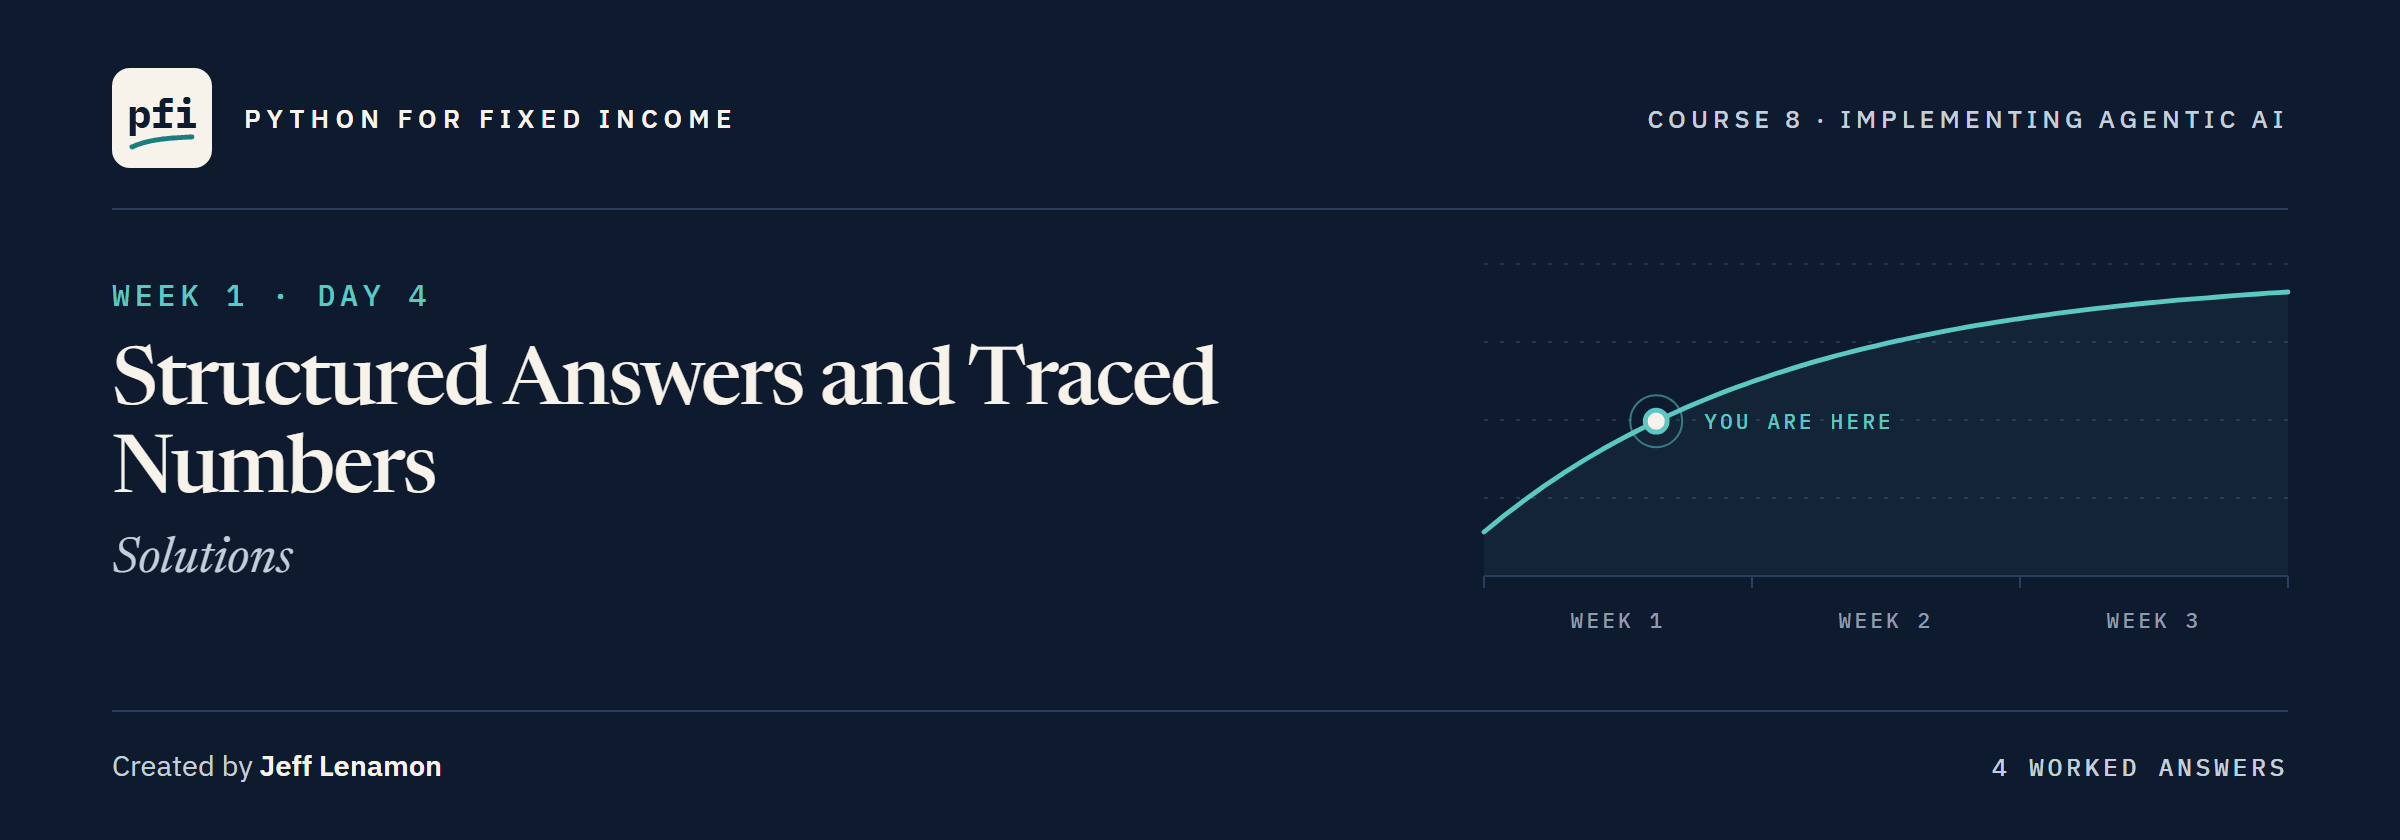

# Structured Answers and Traced Numbers: Solutions

Week 1, Day 4. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day4/04_structured_answers_and_traced_numbers_solutions.ipynb)

# Setting Up

## Course Setup

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text as JSON, patterns, wrapping text, dates, and numbers written in decimal (decimal)
import json
import re
import textwrap
from datetime import date
from decimal import ROUND_HALF_UP, Decimal

# to load and work with the data
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## The Model, Live or Replayed

In [3]:
# the model: with your own key each request goes to the model; without one, the course's saved runs answer it
import hashlib
import json
import sys

# Colab does not come with these: this installs them there (on your machine, requirements.txt already did)
if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install --quiet openai==3.26.0 python-dotenv==1.2.4")

import httpx2
from dotenv import dotenv_values
from openai import OpenAI

# today's saved runs: one file for each request the course sent, named by the request's fingerprint
RUNS = DATA + "course8_agent_runs/day04/"
MODEL = "gpt-4.1-mini"


def fingerprint(request):
    """The SHA-256 of a request's method, path and JSON body; never its headers, which carry the key."""
    text = json.dumps({"method": request.method, "path": request.url.path, "body": json.loads(request.content)},
                      sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode()).hexdigest()


def replay(request):
    """The saved response to exactly this request."""
    saved = pd.read_json(RUNS + fingerprint(request) + ".json", typ="series")
    return httpx2.Response(200, json=saved["response"])


# your own key, if you have one: an environment variable, my_bondmath\.env (Course 3), or Colab's Secrets panel
key = os.environ.get("OPENAI_API_KEY") or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENAI_API_KEY")
if not key and "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = userdata.get("OPENAI_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None

if key:
    client = OpenAI(api_key=key)
    MODE = "live"
else:
    saved_runs = httpx2.MockTransport(replay)
    client = OpenAI(api_key="replay", http_client=httpx2.Client(transport=saved_runs))
    MODE = "replay"
print(f"Mode: {MODE}.")

Mode: replay.


## Today's Answer and Checks

In [4]:
# the teaching notebook's Figure and DeskAnswer, as written there
import pydantic


class Figure(pydantic.BaseModel):
    """One number in an answer, with the tool request whose result it came from."""
    model_config = pydantic.ConfigDict(extra="forbid")
    name: str = pydantic.Field(description="what the number is, for example 'DV01 of the 2031 bond'")
    value: float = pydantic.Field(description="the number, written to the decimals stated in the text")
    unit: str = pydantic.Field(description="the unit as the tool result's key ends: per_100, pct, bp, usd, years")
    tool_call_id: str = pydantic.Field(description="the id of the tool request whose result holds the number")


class DeskAnswer(pydantic.BaseModel):
    """An agent's answer: the text, every number in it as a Figure, and the documents or files it used."""
    model_config = pydantic.ConfigDict(extra="forbid")
    text: str = pydantic.Field(description="the answer in plain sentences")
    figures: list[Figure] = pydantic.Field(description="every number the text states")
    sources: list[str] = pydantic.Field(description="the files, sections, or statement dates used")

In [5]:
# the teaching notebook's checks, as written there
NUMBER = r"\b\d+(?:\.\d+)?"


def tool_results(run):
    """Each tool request id of a run, with the result its tool message carried."""
    return {m["tool_call_id"]: json.loads(m["content"]) for m in run["messages"] if m["role"] == "tool"}


def rounds_to(value, written):
    """True when value, rounded half away from zero to the decimals of written, equals written."""
    return Decimal(repr(value)).quantize(Decimal(written), rounding=ROUND_HALF_UP) == Decimal(written)


def check_figures(answer, run):
    """One row per figure: its request in the run, a number there that rounds to it, that key ending in its unit."""
    results = tool_results(run)
    rows = []
    for figure in answer.figures:
        result = results.get(figure.tool_call_id, {})
        keys = [key for key, value in result.items() if isinstance(value, float) and rounds_to(value, repr(figure.value))]
        rows.append({"name": figure.name, "value": figure.value, "unit": figure.unit,
                     "cited": figure.tool_call_id in results, "value_matches": len(keys) > 0,
                     "unit_matches": any(key.endswith("_" + figure.unit) for key in keys)})
    table = pd.DataFrame(rows)
    table["passed"] = table["cited"] & table["value_matches"] & table["unit_matches"]
    return table


def numbers_untraced(text, run):
    """The numbers of a text that the question does not write and no tool result of the run rounds to."""
    asked = re.findall(NUMBER, run["messages"][1]["content"])
    values = [v for result in tool_results(run).values() for v in result.values() if isinstance(v, float)]
    return [n for n in re.findall(NUMBER, text) if n not in asked and not any(rounds_to(v, n) for v in values)]

In [6]:
# today's structured DTS run, read from its last saved exchange: the request holds the run's messages, the response its answer
dts_saved = pd.read_json(RUNS + "4d89098cb4e154951d4bf336dae2eb9445a1125e24b5fad6e95fa6889082a5c3.json", typ="series")
run_dts = {"messages": dts_saved["request"]["messages"]}
answer_dts = DeskAnswer.model_validate_json(dts_saved["response"]["choices"][0]["message"]["content"])

# Wrapping Up

## Exercises

In [7]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Day 3's DTS Answer, Written as Figures**

In [8]:
# agent answer
# Day 3's saved exchange for its DTS question: its last request holds the run's messages, its response the answer
day3_dts = pd.read_json(DATA + "course8_agent_runs/day03/219091039195904d392178f4c45eb5d51c8b497ae4a51a4fe7d5eabb8f150ff4.json", typ="series")
run_day3_dts = {"messages": day3_dts["request"]["messages"]}
answer_day3_dts = day3_dts["response"]["choices"][0]["message"]["content"]
print(answer_day3_dts)
print(tool_results(run_day3_dts))

As of 2026-09-30, the DTS (duration times spread) of bond 99080CAE8, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp, is approximately 680.165 years times basis points. The spread duration in years is approximately 4.627.
{'call_RtyKLWwHoj6bYlggE8UPAihf': {'spread_duration_years': 4.626971, 'tool_call_id': 'call_RtyKLWwHoj6bYlggE8UPAihf'}, 'call_4Bfb4qYtc8O7ybKyX6iMasji': {'dts_years_bp': 680.164737, 'tool_call_id': 'call_4Bfb4qYtc8O7ybKyX6iMasji'}}


In [9]:
# the two numbers as figures, each citing the request whose result holds it at the text's rounding
by_hand = DeskAnswer(text=answer_day3_dts, sources=["2026-09-30"], figures=[
    Figure(name="DTS of bond 99080CAE8", value=680.165, unit="years_bp", tool_call_id="call_4Bfb4qYtc8O7ybKyX6iMasji"),
    Figure(name="Spread duration of bond 99080CAE8", value=4.627, unit="years", tool_call_id="call_RtyKLWwHoj6bYlggE8UPAihf")])
table_ex1 = check_figures(by_hand, run_day3_dts)
ex1_run = [len(numbers_untraced(answer_day3_dts, run_day3_dts)), int(table_ex1["passed"].sum())]
print(ex1_run)
table_ex1

[0, 2]


,name,value,unit,cited,value_matches,unit_matches,passed
0,DTS of bond 99080CAE8,680.165,years_bp,True,True,True,True
1,Spread duration of bond 99080CAE8,4.627,years,True,True,True,True


Both figures pass at the text's own rounding: the check accepts a stated rounding, and the citations make it checkable.

In [10]:
check("Exercise 1 the untraced numbers and the figures that pass", ex1_run, [0, 2])

Exercise 1 the untraced numbers and the figures that pass: correct


### Exercise 2

**A Figure in the Wrong Unit**

In [11]:
# the first figure's unit changed in a copy
wrong_unit = answer_dts.model_copy(deep=True)
wrong_unit.figures[0].unit = "pct"
table_ex2 = check_figures(wrong_unit, run_dts)
ex2_unit = table_ex2.loc[0, ["cited", "unit_matches", "passed"]].tolist()
print(ex2_unit)
table_ex2

[True, False, False]


,name,value,unit,cited,value_matches,unit_matches,passed
0,Spread duration in years of bond 99080CAE8,4.626971,pct,True,True,False,False
1,DTS of bond 99080CAE8,680.164737,years_bp,True,True,True,True


The request is cited and the value matches, but `spread_duration_years` does not end in `_pct`.

In [12]:
check("Exercise 2 cited, unit_matches and passed", ex2_unit, [True, False, False])

Exercise 2 cited, unit_matches and passed: correct


### Exercise 3

**The Figures That Fail**

In [13]:
# the names of the rows whose passed is False (~ turns True into False, Course 1)
def failed_figures(table):
    """The names of a check table's figures that did not pass."""
    return table.loc[~table["passed"], "name"].tolist()


ex3_failed = failed_figures(table_ex2)
print(ex3_failed)

['Spread duration in years of bond 99080CAE8']


In [14]:
check("Exercise 3 the figures that fail", ex3_failed, ["Spread duration in years of bond 99080CAE8"])

Exercise 3 the figures that fail: correct


### Exercise 4: AI check

**A Figure Check That Forgives Too Much**

In [15]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def figure_matches(figure_value, tool_value):
    """True when a figure is the tool's value at the figure's own decimals: 0.0436 passes against 0.043625, 0.0437 fails (a wrong digit)."""
    # round both to 2 decimals, so small differences do not matter
    return round(figure_value, 2) == round(tool_value, 2)


print("0.0437 against 0.043625:", figure_matches(0.0437, 0.043625))

0.0437 against 0.043625: True


The docstring says 0.0437 fails, and the check passes it: at 2 decimals both are 0.04.

The wrong idea is the comment: a fixed 2 decimals forgives a wrong digit; the figure's own decimals do not.

In [16]:
# the fix: round the tool's value half away from zero to the figure's own decimals
def figure_matches(figure_value, tool_value):
    """True when a figure is the tool's value at the figure's own decimals: 0.0436 passes against 0.043625, 0.0437 fails (a wrong digit)."""
    return rounds_to(tool_value, repr(figure_value))


ex4_matches = [figure_matches(value, 0.043625) for value in (0.0436, 0.0437, 0.04)]
print(ex4_matches)

[True, False, True]


In [17]:
check("Exercise 4 the fixed check on 0.0436, 0.0437 and 0.04", ex4_matches, [True, False, True])

Exercise 4 the fixed check on 0.0436, 0.0437 and 0.04: correct


## Congratulations!

Every exercise worked: Day 3's rounded answer written as figures that pass, a wrong unit caught, the failing figures listed, and an AI's check that forgave a wrong digit, fixed at the figure's own decimals.

[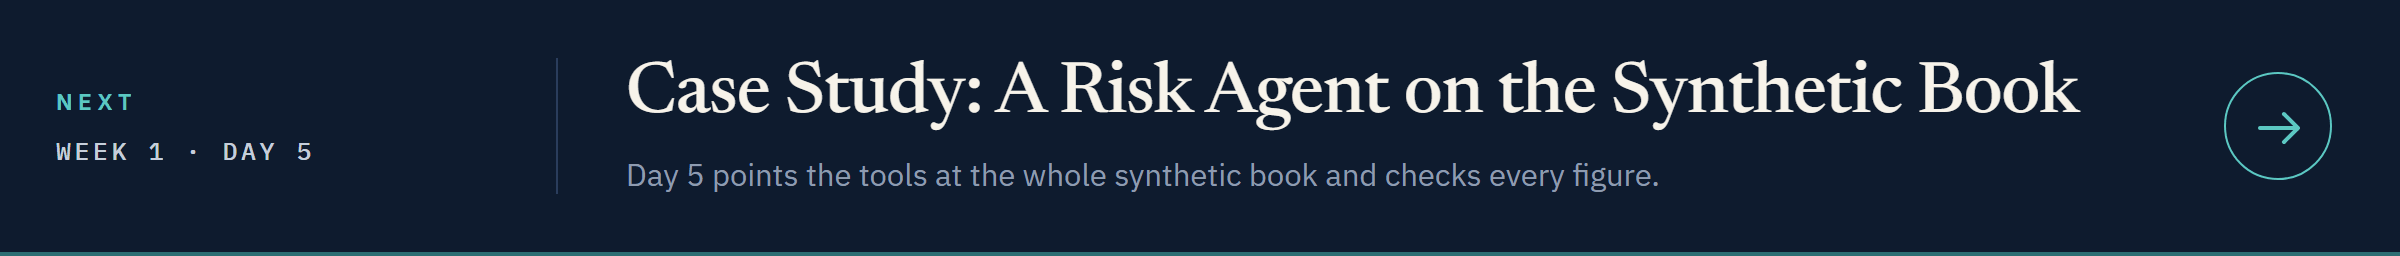](../day5/05_case_study_a_risk_agent_on_the_synthetic_book.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day5/05_case_study_a_risk_agent_on_the_synthetic_book.ipynb)